# Tunneling through a barrier

A wavepacket hits a rectangular barrier of height $V_0$ and width $a$. Classically, a particle with
energy $E < V_0$ is always reflected. Quantum mechanically, part of the packet tunnels through.

For a plane wave with energy $E = k^2/2$ the transmission probability is

$$T(E) = \left[1 + \frac{V_0^2 \sinh^2(\kappa a)}{4E(V_0 - E)}\right]^{-1}, \qquad \kappa = \sqrt{2(V_0 - E)},$$

for $E < V_0$, and the same expression with $\sinh \to \sin$ and $\kappa \to \sqrt{2(E-V_0)}$, $V_0 - E \to E - V_0$ for $E > V_0$.
A wavepacket contains many energies, so its transmission is $T(E)$ averaged over its momentum distribution.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML

import so_schroedinger as so

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["animation.embed_limit"] = 50  # MB
plt.rcParams["figure.dpi"] = 72

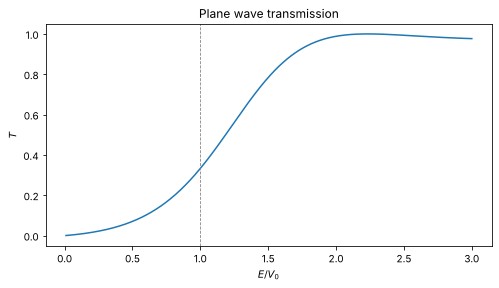

In [2]:
V0, a = 1.0, 2.0
barrier = so.BoxPotential(pos=0.0, width=a / 2, height=V0)  # width is the half width


def T_plane_wave(E, V0=V0, a=a):
    E = np.asarray(E, dtype=complex)
    q = np.sqrt(2 * (V0 - E))  # imaginary above the barrier
    T = 1 / (1 + V0**2 * np.sinh(q * a) ** 2 / (4 * E * (V0 - E)))
    return np.real(T)


E = np.linspace(0.01, 3.0, 500)
plt.plot(E / V0, T_plane_wave(E))
plt.axvline(1.0, c="gray", lw=0.8, ls="--")
plt.xlabel("$E/V_0$")
plt.ylabel("$T$")
plt.title("Plane wave transmission");

## One packet below the barrier

The packet starts far left of the barrier with mean energy $E_0 = 0.6\,V_0$. Absorbing potentials
at both boundaries swallow the transmitted and reflected parts before they wrap around the periodic grid.

In [3]:
size = (-150.0, 150.0)
absorber = so.ExpAbsorber1d(0.0, -0.5, 10.0, 10.0, *size)


def make_grid(E0, sigma=8.0):
    psi0 = so.Gaussian1d(x0=-50.0, sigma=sigma, p0=np.sqrt(2 * E0))
    return so.Grid1d(size, 2**12, barrier, psi0, absorber=absorber)


grid = make_grid(0.6 * V0)
anim = so.animate1d(grid, so.SplitOperator(), dt=0.05, n_frames=80, steps_per_frame=20)
HTML(anim.to_jshtml())

## Transmission versus energy

To measure the transmission we propagate until the packet has left the barrier region and integrate
$|\psi|^2$ to the right of the barrier, before the transmitted part reaches the absorber.
The expected value is the plane wave result averaged over the packet's momentum distribution
$|\phi(p)|^2 \propto \exp(-\sigma^2 (p - p_0)^2)$.

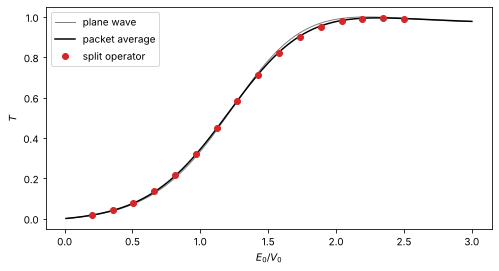

In [4]:
def transmission(E0, sigma=8.0, dt=0.05, grid=None):
    grid = make_grid(E0, sigma) if grid is None else grid
    p0 = np.sqrt(2 * E0)
    t_end = 100.0 / p0  # packet center is then 50 to the right of the barrier
    so.SplitOperator().propagate(grid, dt, int(t_end / dt))
    right = grid.x_vals > 0.0  # the absorber is far away, so the barrier edge does not matter
    return np.sum(grid.density[right]) * grid.dx


def T_packet(E0, sigma=8.0, V0=V0, a=a):
    p0 = np.sqrt(2 * E0)
    p = np.linspace(p0 - 6 / sigma, p0 + 6 / sigma, 2001)
    weight = np.exp(-(sigma**2) * (p - p0) ** 2)
    p, weight = p[p > 0], weight[p > 0]
    return np.sum(T_plane_wave(p**2 / 2, V0, a) * weight) / np.sum(weight)


E0s = np.linspace(0.2, 2.5, 16) * V0
T_num = [transmission(E0) for E0 in E0s]

plt.plot(E / V0, T_plane_wave(E), c="gray", lw=1, label="plane wave")
plt.plot(E / V0, [T_packet(e) for e in E], "k-", lw=1.5, label="packet average")
plt.plot(E0s / V0, T_num, "o", c="tab:red", label="split operator")
plt.xlabel("$E_0/V_0$")
plt.ylabel("$T$")
plt.legend();

The oscillations above the barrier are transmission resonances: whenever the barrier width is a
multiple of half the wavelength above the barrier, $\sqrt{2(E-V_0)}\,a = n\pi$, the packet passes
completely. A wavepacket averages over these resonances, which washes them out.

## Explore interactively

A 1d run takes only a fraction of a second, so it can follow sliders live. Move the barrier height,
width and packet energy, and the measured transmission (red dot) moves along the packet-averaged curve.
The sliders need `ipywidgets` (included in `pip install ".[notebooks]"`); without it the cell draws a
single static figure.

/tmp/ipykernel_3108/1118988136.py:8: RuntimeWarning: invalid value encountered in divide
  T = 1 / (1 + V0**2 * np.sinh(q * a) ** 2 / (4 * E * (V0 - E)))


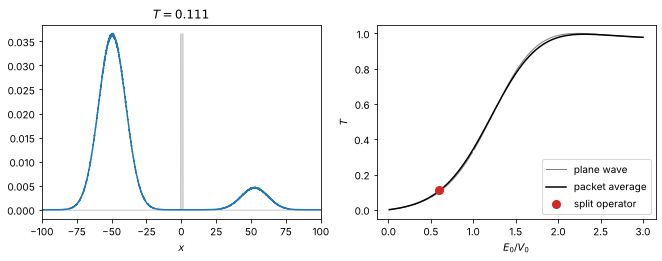

In [5]:
def explore(V0=1.0, a=2.0, E0_over_V0=0.6):
    E0 = E0_over_V0 * V0
    psi0 = so.Gaussian1d(x0=-50.0, sigma=8.0, p0=np.sqrt(2 * E0))
    grid = so.Grid1d(size, 2**12, so.BoxPotential(0.0, a / 2, V0), psi0, absorber=absorber)
    T = transmission(E0, grid=grid)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
    ax1.plot(grid.x_vals, grid.density)  # after the collision
    ax1.fill_between(grid.x_vals, 0, np.real(grid.V) / V0 * grid.density.max(), color="gray", alpha=0.3)
    ax1.set(xlim=(-100, 100), xlabel="$x$", title=f"$T = {T:.3f}$")
    E = np.linspace(0.01, 3.0, 300) * V0
    ax2.plot(E / V0, T_plane_wave(E, V0, a), c="gray", lw=1, label="plane wave")
    ax2.plot(E / V0, [T_packet(e, V0=V0, a=a) for e in E], "k-", lw=1.5, label="packet average")
    ax2.plot(E0_over_V0, T, "o", c="tab:red", ms=8, label="split operator")
    ax2.set(xlabel="$E_0/V_0$", ylabel="$T$", ylim=(-0.05, 1.05))
    ax2.legend(loc="lower right")
    plt.show()


try:
    from ipywidgets import FloatSlider, interact
except ImportError:
    explore()
else:
    interact(
        explore,
        V0=FloatSlider(value=1.0, min=0.2, max=3.0, step=0.1, continuous_update=False, description="V0"),
        a=FloatSlider(value=2.0, min=0.5, max=5.0, step=0.1, continuous_update=False, description="width a"),
        E0_over_V0=FloatSlider(value=0.6, min=0.1, max=3.0, step=0.05, continuous_update=False, description="E0/V0"),
    )